private -> ABC 1234
public utility -> DEF 5678
government -> GHI 9612
others -> JKL 3456
diplomatic -> MNO 7896


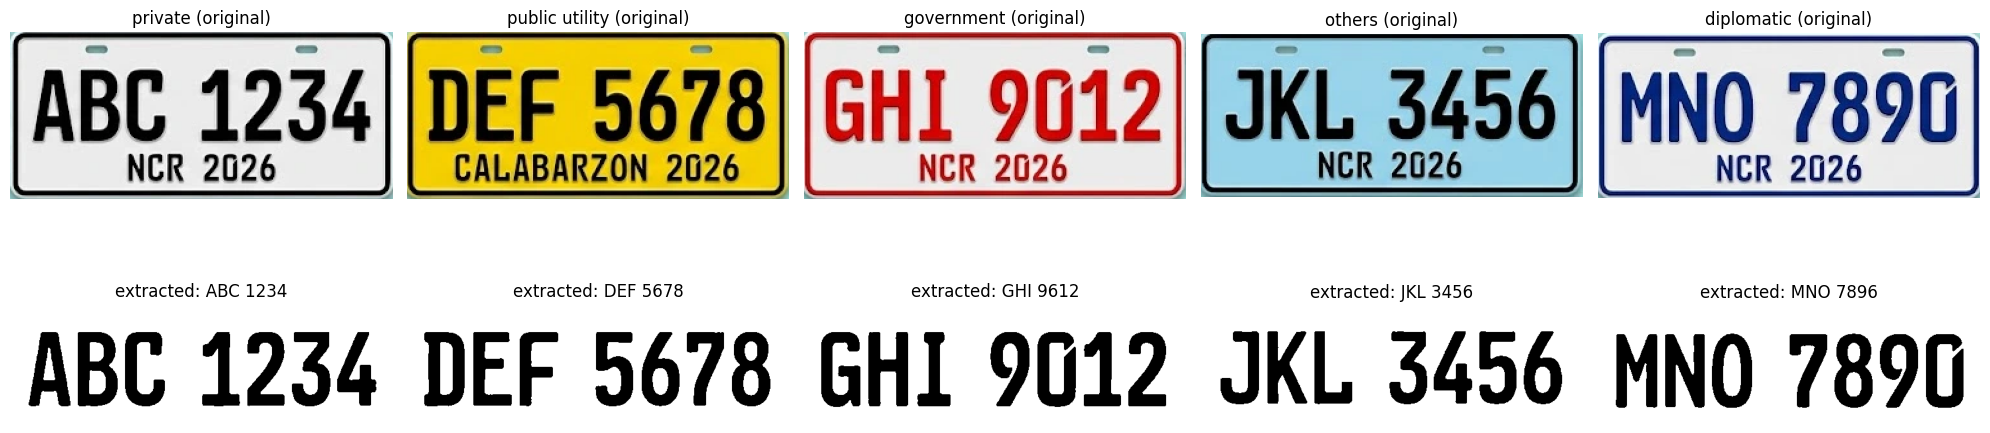


Extracted characters: ['ABC 1234', 'DEF 5678', 'GHI 9612', 'JKL 3456', 'MNO 7896']
  private: ABC 1234
  public utility: DEF 5678
  government: GHI 9612
  others: JKL 3456
  diplomatic: MNO 7896


In [1]:
import cv2
import pytesseract
import matplotlib.pyplot as plt

# tell python where tesseract is (this is for windows, delete this line if it works without it)
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# the one pic that has all the plates
img = cv2.imread("plate_number.webp")
if img is None:
    raise FileNotFoundError("can't open the pic, check the file name and folder")

# where each plate is inside the big pic: (left, top, right, bottom) in pixels
plates = {
    "private":        (35, 98, 332, 228),
    "public utility": (365, 98, 662, 228),
    "government":     (695, 98, 992, 228),
    "others":         (192, 330, 496, 460),
    "diplomatic":     (535, 328, 836, 458),
}

def read_plate(plate):
    # cut out the middle part, this is where the plate number is
    h, w = plate.shape[:2]
    crop = plate[int(h * 0.15):int(h * 0.68), int(w * 0.05):int(w * 0.95)]

    # make it bigger so the letters are easier to read
    crop = cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

    # gray, then a little blur, then black and white
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # if there's more black than white, flip it (we want black letters on white)
    if cv2.countNonZero(bw) < bw.size / 2:
        bw = cv2.bitwise_not(bw)

    # put a white border around it
    bw = cv2.copyMakeBorder(bw, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=255)

    # psm 7 = read it as one line
    text = pytesseract.image_to_string(bw, config="--psm 7").strip()
    return bw, text

# go through every plate, read it, and show it
# top row = original plate, bottom row = what was extracted
fig, axs = plt.subplots(2, len(plates), figsize=(4 * len(plates), 6))
results = []                            # keeps every extracted plate text

for i, (name, (x1, y1, x2, y2)) in enumerate(plates.items()):
    plate = img[y1:y2, x1:x2]          # cut the plate out of the big pic
    bw, text = read_plate(plate)
    results.append((name, text))
    print(name, "->", text)

    # original plate (cv2 is BGR, matplotlib wants RGB)
    axs[0, i].imshow(cv2.cvtColor(plate, cv2.COLOR_BGR2RGB))
    axs[0, i].set_title(name + " (original)")
    axs[0, i].axis("off")

    # cleaned-up image that was fed to the OCR + the extracted characters
    axs[1, i].imshow(bw, cmap="gray")
    axs[1, i].set_title("extracted: " + text)
    axs[1, i].axis("off")

plt.tight_layout()
plt.show()

# list of extracted characters, printed at the end
extracted = [text for name, text in results]
print("\nExtracted characters:", extracted)
for name, text in results:
    print(f"  {name}: {text}")